<a href="https://colab.research.google.com/github/nathaniel-fruni/diplomova-praca/blob/main/data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pochopenie dát

In [ ]:
# importy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from datasets import load_dataset
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_colwidth", 250)

## Načítanie a rozdelenie dát

In [ ]:
ds = load_dataset("TUKE-KEMT/senti-sk")

train = ds["train"].to_pandas()
test = ds["test"].to_pandas()

df = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)

README.md:   0%|          | 0.00/705 [00:00<?, ?B/s]

train.json:   0%|          | 0.00/4.03M [00:00<?, ?B/s]

test.json:   0%|          | 0.00/989k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/19148 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4677 [00:00<?, ? examples/s]

In [ ]:
overview = (
    df.groupby("split")
      .agg(rows=("id", "size"))
      .reindex(list(ds))
      .assign(share=lambda t: t["rows"] / t["rows"].sum())
)

display(
    overview.style
        .format({"share": "{:.0%}", "rows": "{:,}"})
        .bar(subset="rows")
)

print(f"\nCelkový počet záznamov: {len(df):,}")

,rows,share
split,,
train,"19,148",80%
test,"4,677",20%



Celkový počet záznamov: 23,825


## Preskúmanie stĺpcov a hodnôt

In [ ]:
# typy, počty a príklady stĺpcov
cols = df.drop(columns="split")

schema = pd.DataFrame({
    "hf_type": {k: v.dtype for k, v in ds["train"].features.items()},
    "pandas_dtype": cols.dtypes.astype(str),
    "non_null": cols.notna().sum(),
    "missing": cols.isna().mean(),
    "unique": cols.nunique(),
    "example": cols.iloc[0],
})

display(
    schema.style
        .format({"missing": "{:.1%}", "non_null": "{:,}", "unique": "{:,}"})
        .background_gradient(subset="missing", cmap="Reds", vmin=0, vmax=1)
)

,hf_type,pandas_dtype,non_null,missing,unique,example
id,int64,int64,"23,825",0.0%,"23,822",1467810917
label,string,object,"23,825",0.0%,3,negative
user,string,object,"23,825",0.0%,"13,121",mattycus
created_at,timestamp[s],datetime64[s],"23,825",0.0%,"13,964",2009-04-06 22:19:53
text,string,object,"23,825",0.0%,"22,592",Marek Kollar ..on je BUDAR


### id

Z predchádzajúcej tabuľky je možné vidieť, že v datasete existujú 3 identické id. Je preto potrebné zistiť, či ide o duplicitné záznamy alebo len rovnaké id s rozdielnym obsahom ďalších stĺpcov.

In [ ]:
cols = ["id", "label", "user", "created_at", "text"]
print(f"Úplne zhodné záznamy: {df.duplicated(subset=cols).sum()}")

Úplne zhodné záznamy: 3


Kontrola potvrdzuje, že ide o **3 duplicitné záznamy**, ktoré bude potrebné z datasetu odstrániť.

## Label (označenie sentimentu)

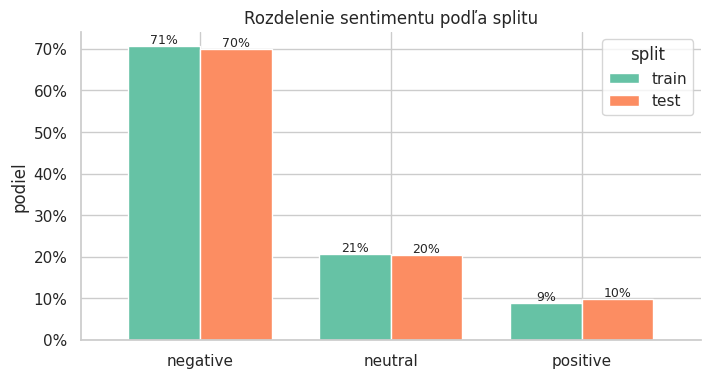

In [ ]:
dist = pd.crosstab(df["label"], df["split"], normalize="columns")[list(ds)]

ax = dist.plot.bar(rot=0, figsize=(8, 4), width=0.75)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Rozdelenie sentimentu podľa splitu", xlabel="", ylabel="podiel")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], fontsize=9)
sns.despine()
plt.show()

Dataset je **výrazne nevyvážený**: prevažujú negatívne komentáre (~70 %), neutrálne tvoria ~21 % a pozitívne len ~9 %. Rozdelenie tried je v train aj test takmer totožné, takže testovacia množina je reprezentatívna, no pri modelovaní bude potrebné nevyváženosť zohľadniť.

### User (používateľ)

Podľa tabuľky je unikátnych používateľov len 13121, čo tvorí približne 55,1% datasetu, čo naznačuje, že jeden používateľ zvyčajne prispeje viacerými komentármi. Nasledujúci graf a základné štatistiky lepšie zobrazia počty používateľov k počtu komentárov.

,count,mean,std,min,25%,50%,75%,max
komentáre na používateľa,13121.0,1.82,2.15,1.0,1.0,1.0,2.0,47.0


Top 10 používateľov tvorí 1.3% dát


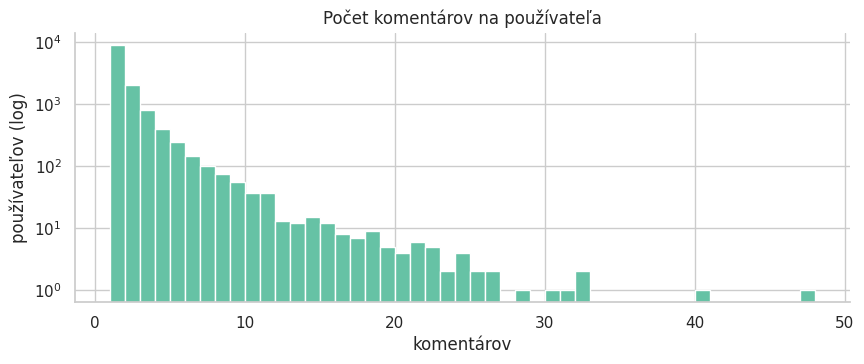

In [ ]:
per_user = df["user"].value_counts()

display(per_user.describe().to_frame("komentáre na používateľa").T.round(2))
print(f"Top 10 používateľov tvorí {per_user.head(10).sum() / len(df):.1%} dát")

ax = per_user.plot.hist(bins=range(1, per_user.max() + 2), log=True, figsize=(10, 3.5))
ax.set(title="Počet komentárov na používateľa", xlabel="komentárov", ylabel="používateľov (log)")
sns.despine()
plt.show()

In [ ]:
shared = set(train["user"]) & set(test["user"])
print(f"Používatelia v train aj test: {len(shared):,} ({len(shared) / df['user'].nunique():.1%})")

Používatelia v train aj test: 0 (0.0%)


In [ ]:
users = df["user"].drop_duplicates()
n_words = users.str.split().str.len()

display(n_words.value_counts().sort_index().rename_axis("slov v mene").to_frame("používateľov"))

,používateľov
slov v mene,
1,69
2,11297
3,1703
4,48
5,3
19,1


In [ ]:
with pd.option_context("display.max_rows", 150):
    display(users[n_words.isin([1, 4, 5, 19])].to_frame().assign(slov=n_words).sort_values("slov"))

,user,slov
0,mattycus,1
1,ElleCTF,1
3,mybirch,1
4,coZZ,1
6,erinx3leannexo,1
5,2Hood4Hollywood,1
7,pardonlauren,1
8,TLeC,1
12,armotley,1
9,robrobbierobert,1


Väčšina používateľov (medián 1, 75 % ≤ 2) prispela **1 alebo 2 komentármi**. Rozdelenie má dlhý chvost s **maximom 47 komentárov**. Najaktívnejší používatelia tvoria len malú časť dát (**top 10 = 1,3 %**), takže dataset nie je zaujatý v prospech niekoľkých autorov.

Medzi train a test neexistuje **žiadny prekryv používateľov**. Testovacia množina tak meria schopnosť modelu generalizovať na nových používateľov a nehrozí únik informácií cez štýl písania konkrétnych ľudí.

Počty slov mena poukazujú na to, že najbežnejšie sú 2 a 3 slovné mená, kde je meno a priezvisko. Ostatných je zanedbateľné množstvo (0,9%) a preto sa dajú manuálne preskúmať a zvážiť ich odstránenie z datasetu.

## Created_at (dátum zverejnenia komentára)

Z tabuľky je možné vidieť, že unikátnych časových známok zverejnenia komentára je len 13 964. Je preto potrebné bližšie preskúmať akým spôsobom sú časové známky zapísané. Môže ísť len o zapisovanie dátumu, hodiny a minúty bez sekúnd. V takom prípade je reálne, že viacero príspevkov vzniklo v rovnakú minútu.

In [ ]:
display(
    df.groupby(df["created_at"].dt.year.rename("rok"))["created_at"]
      .agg(počet="size", nulové_sekundy=lambda s: (s.dt.second == 0).mean())
      .style.format({"nulové_sekundy": "{:.1%}"})
)

,počet,nulové_sekundy
rok,,
2009,61,1.6%
2020,23764,100.0%


In [ ]:
ts = df.loc[df["created_at"].dt.year == 2020, "created_at"]
per_minute = ts.value_counts()

print(f"Komentárov: {len(ts):,} | unikátnych minút: {per_minute.size:,} | max v jednej minúte: {per_minute.max()}")

Komentárov: 23,764 | unikátnych minút: 13,930 | max v jednej minúte: 15


Všetky časové známky z roku 2020 majú nulové sekundy, **čas je teda zaznamenaný s presnosťou na minúty**. Na 23 764 komentárov pripadá 13 930 unikátnych minút s **maximom 15 komentárov za minútu**, čo zodpovedá bežnej aktivite v diskusii. Zhody časov sú teda dôsledkom zaokrúhlenia, nie chybou v dátach.

Odlišne sa správa **61 záznamov z roku 2009**: nulové sekundy má iba jeden z nich (1,6 %), čo zodpovedá **náhodnému rozdeleniu sekúnd**. Tieto záznamy sú teda zapísané s inou presnosťou než zvyšok datasetu a navyše **časovo úplne vybočujú**, keďže **všetky** ostatné komentáre pochádzajú z roku **2020**. Odlišný formát aj obdobie naznačujú, že môže ísť o záznamy iného pôvodu alebo o chybné metadáta.

In [ ]:
old = df[df["created_at"].dt.year == 2009]

In [ ]:
old_users = set(old["user"])
new_users = set(df.loc[df["created_at"].dt.year == 2020, "user"])
print(f"Používateľov v 2009: {len(old_users)} | z toho aj v 2020: {len(old_users & new_users)}")

Používateľov v 2009: 61 | z toho aj v 2020: 0


In [ ]:
print(f"Texty z 2009, ktoré sú aj v 2020: {old['text'].isin(df.loc[df['created_at'].dt.year == 2020, 'text']).sum()} z {len(old)}")
display(old["label"].value_counts(normalize=True).to_frame("podiel").style.format("{:.0%}"))

Texty z 2009, ktoré sú aj v 2020: 6 z 61


,podiel
label,
positive,51%
negative,49%


In [ ]:
dup_texts = old.loc[old["text"].isin(df.loc[df["created_at"].dt.year == 2020, "text"]), "text"]
sub = df[df["text"].isin(dup_texts)]
display(pd.crosstab([sub["text"], sub["created_at"].dt.year.rename("rok")], sub["label"]))

label              negative  neutral  positive
text         rok                              
             2009         1        0         0
             2020        10        5         1
Ano          2009         1        0         0
             2020        14        7         2
Dakujem      2009         0        0         1
             2020         0        1         1
Máte pravdu  2009         0        0         1
             2020         1        0         0
Ste jednicka 2009         0        0         1
             2020         0        0         1
Super        2009         0        0         1
             2020        10        4        10

In [ ]:
old = df[df["created_at"].dt.year == 2009].sort_values("created_at")

with pd.option_context("display.max_rows", None):
    display(old[["created_at", "user", "label", "split", "text"]])

,created_at,user,label,split,text
19148,2009-04-06 22:19:49,scotthamilton,negative,test,Pánovi Bánovi veľmi chýba slušná výchova a rešpekt. Pani prezidentka nie je jeho dieťa aby sa s ňou rozprával týmto tónom a ešte ju aj manipulatívne úkoloval.
0,2009-04-06 22:19:53,mattycus,negative,train,Marek Kollar ..on je BUDAR
1,2009-04-06 22:19:57,ElleCTF,negative,train,Peťo Vinci dosť nešťastne vyjadrenie.
19149,2009-04-06 22:19:57,Karoli,negative,test,Rony Iron a vy máte nešťastné rozmýšľanie. Komu tým akože pomôžete keď nepôjdete voliť?? To je také ťažké sa premôcť a ísť?? Každý prepadnúť hlas ide smeru lsns a sns. Potom nás už ani prezidentka nezachráni.
2,2009-04-06 22:20:00,Janka Koreňová áno a podporiť politiku eú asi neviete čo ťa na nás chystalen aby ste toho raz nelutovali,negative,train,
3,2009-04-06 22:20:03,mybirch,negative,train,Viac-menej si myslím
4,2009-04-06 22:20:03,coZZ,negative,train,Harry Cefi Váš problém je nevedomosť. Nerozumiete rozdielu stíhaný / Kiska/ a už obžalovaný / Kotleba/. Tu neriešte prezupciu neviny
5,2009-04-06 22:20:05,2Hood4Hollywood,negative,train,Harry Cefi Prosím vás a ako to mala povedať? Keď dostala otázku akú dostala? Viete my
19150,2009-04-06 22:20:09,mimismo,negative,test,Harry Cefi Kiska čestný človek? Čo sa to pre Boha deje...
6,2009-04-06 22:20:16,erinx3leannexo,negative,train,Ano


Šesť textov z roku 2009 sa vyskytuje aj v dátach z 2020, ide o krátke všeobecné komentáre. Ich labely z 2009 zodpovedajú významu textu.

Podrobnejšia kontrola 61 záznamov z roku 2009 ukázala, že ich metadáta (id, používateľ, čas) zrejme pochádzajú z iného datasetu. Postihnuté sú prvé riadky oboch splitov (46 v train, 15 v test), ide teda o systematickú chybu pri tvorbe datasetu. Väčšina týchto záznamov obsahuje platné slovenské komentáre so zmysluplnými labelmi, ich metadáta však nie sú spoľahlivé. Dva záznamy obsahujú pôvodné anglické tweety, jeden má text posunutý do stĺpca user a jeden má prázdny text.

## Text (text komentára)

Podľa tabuľky existuje 1233 textov, ktoré sa v texte vyskytujú viac ako raz. Je potrebné preskúmať, či ide o duplicity (rovanké aj iné stĺpce záznamu) alebo či je to len rovnaký text, napríklad krátke všeobecné texty. Tiež je potrebné preskúmať, či existujú komentáre s prázdnym textom.

In [ ]:
print(f"Prázdne texty: {(df['text'].str.strip() == '').sum()}")

Prázdne texty: 17


In [ ]:
empty = df[df["text"].str.strip() == ""]
display(empty[["created_at", "user", "label", "split", "text"]])

,created_at,user,label,split,text
2,2009-04-06 22:20:00,Janka Koreňová áno a podporiť politiku eú asi neviete čo ťa na nás chystalen aby ste toho raz nelutovali,negative,train,
938,2020-10-02 17:00:00,Dusan Pajdlhauser,negative,train,
2618,2020-10-18 17:45:00,Speidy Gonzales,negative,train,
2643,2020-10-18 12:37:00,Antonia Orosova,neutral,train,
3750,2020-10-26 17:20:00,Magda Gojdicova Pasnisinova,positive,train,
4348,2020-11-05 12:05:00,Dominik Brenkus,neutral,train,
6569,2020-10-19 05:36:00,Kamila Tomaskova,negative,train,
7251,2020-10-20 05:14:00,Pavol Facko,negative,train,
8557,2020-10-22 20:24:00,Peter Laťák,neutral,train,
8802,2020-10-23 18:59:00,Peter Pepec,negative,train,


In [ ]:
dup = df[df["text"].duplicated(keep=False) & (df["text"].str.strip() != "")]

In [ ]:
summary = pd.Series({
    "riadky s opakovaným textom": len(dup),
    "rôznych opakovaných textov": dup["text"].nunique(),
    "úplne zhodné záznamy": dup.duplicated(subset=cols).sum(),
    "rovnaký text aj používateľ": dup.duplicated(subset=["text", "user"]).sum(),
}, name="počet").to_frame()

display(summary)

,počet
riadky s opakovaným textom,1556
rôznych opakovaných textov,339
úplne zhodné záznamy,3
rovnaký text aj používateľ,105


In [ ]:
groups = dup.groupby("text").agg(
    výskytov=("id", "size"),
    používateľov=("user", "nunique"),
    labelov=("label", "nunique"),
    splitov=("split", "nunique"),
).sort_values("výskytov", ascending=False)

display(groups.head(20))

,výskytov,používateľov,labelov,splitov
text,,,,
Igor,119,91,3,2
Pán premiér,109,100,3,2
Pán Fico,74,64,3,2
Pán Matovič,48,44,3,2
Pan premier,41,38,2,2
Pan Fico,35,31,3,2
Dúfam,26,25,2,2
Super,25,25,3,2
Pan Matovic,25,23,3,2


In [ ]:
print(f"Texty so zalomením riadku: {df['text'].str.contains('\n').sum()}")

Texty so zalomením riadku: 0


In [ ]:
nonempty = df["text"].str.strip() != ""
words = df.loc[nonempty, "text"].str.split().str.len()
is_dup = df.loc[nonempty, "text"].duplicated(keep=False).map({True: "opakovaný", False: "unikátny"})

display(words.groupby(is_dup).describe().round(1))

,count,mean,std,min,25%,50%,75%,max
text,,,,,,,,
opakovaný,1556.0,1.9,2.7,1.0,1.0,2.0,2.0,47.0
unikátny,22252.0,11.5,14.5,1.0,4.0,7.0,14.0,206.0


In [ ]:
print(f"Texty s rozdielnymi labelmi: {(groups['labelov'] > 1).sum()}")
print(f"Texty v train aj test: {(groups['splitov'] > 1).sum()}")

Texty s rozdielnymi labelmi: 180
Texty v train aj test: 129


In [ ]:
is_rep = df["text"].duplicated(keep=False) & (df["text"].str.strip() != "")
conflict = df.groupby("text")["label"].transform("nunique") > 1

print(f"Opakovaný text, rovnaký label: {(is_rep & ~conflict).sum()}")
print(f"Opakovaný text, rozdielne labely: {(is_rep & conflict).sum()}")

Opakovaný text, rovnaký label: 377
Opakovaný text, rozdielne labely: 1179


Opakovaný text má **1 556 záznamov (339 rôznych textov)**, no úplne zhodné záznamy sú iba 3. Opakované texty sú veľmi krátke (medián 2 slová oproti 7 pri unikátnych) a najčastejšie ide o oslovenia („Igor“, „Pán premiér“, „Pán Fico“) alebo začiatky viet („Dúfam“, „Myslím“). Predpokladáme, že pri zbere dát bol uložený iba prvý riadok komentára a zvyšok sa stratil. Až **180 z 339 opakovaných textov má rozdielne labely**, anotátori zrejme hodnotili celý komentár, ktorý v datasete nie je k dispozícii. Tieto záznamy predstavujú **šum v labeloch** a sú kandidátmi na odstránenie; opakované texty s konzistentným labelom sú legitímne krátke komentáre a možno ich ponechať.

In [ ]:
display(pd.crosstab(df.loc[is_rep & conflict, "split"], df.loc[is_rep & conflict, "label"], margins=True))

label,negative,neutral,positive,All
split,,,,
test,157,55,38,250
train,568,211,150,929
All,725,266,188,1179


Konfliktné záznamy sú rozložené medzi train (929) a test (250) v rovnakom pomere ako celý dataset. Oproti celkovému rozdeleniu tried obsahujú relatívne viac pozitívnych a neutrálnych komentárov, ich odstránenie by teda mierne viac zasiahlo menšinovú pozitívnu triedu (približne 8 – 9 % jej záznamov). Celkové rozdelenie tried by sa však zmenilo len zanedbateľne.

## Ďalšie charakteristiky textu komentárov

### Dĺžka textu

In [ ]:
words = df["text"].str.split().str.len()
display(words.groupby(df["split"]).describe().loc[list(ds)].round(1))

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,19148.0,10.8,14.3,0.0,3.0,7.0,13.0,206.0
test,4677.0,10.9,14.2,0.0,3.0,7.0,13.0,190.0


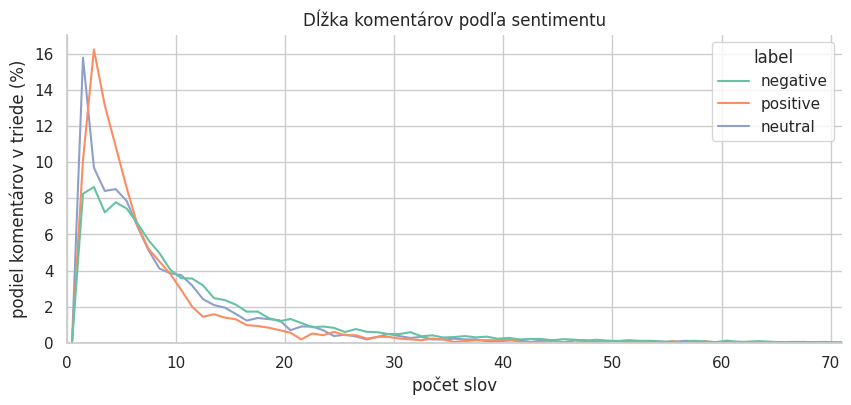

In [ ]:
ax = sns.histplot(
    data=df.assign(words=words), x="words", hue="label",
    binwidth=1, element="poly", fill=False, linewidth=1.5,
    stat="percent", common_norm=False,
)
ax.set_xlim(0, words.quantile(0.99))
ax.set(title="Dĺžka komentárov podľa sentimentu", xlabel="počet slov", ylabel="podiel komentárov v triede (%)")
ax.figure.set_size_inches(10, 4)
sns.despine()
plt.show()

In [ ]:
display(words.groupby(df["label"]).describe()[["mean", "50%", "75%"]].round(1))

,mean,50%,75%
label,,,
negative,11.8,7.0,14.0
neutral,9.1,5.0,11.0
positive,7.4,4.0,8.0


Rozdelenie dĺžky komentárov je v train aj test takmer totožné (**medián 7 slov, priemer ≈ 11**). Rozdelenie je silne zošikmené doprava: **väčšina komentárov je krátka**, štvrtina má najviac 3 slová, no vyskytujú sa aj komentáre s viac ako 200 slovami. Medzi triedami sú rozdiely: **pozitívne komentáre sú najkratšie** (vrchol pri 2 – 3 slovách), neutrálne majú výrazný vrchol pri 1 – 2 slovách, pravdepodobne v dôsledku samostatných oslovení, a **negatívne komentáre sú v priemere dlhšie**, s vyšším zastúpením rozpísaných textov. Dĺžka teda čiastočne súvisí so sentimentom, veľmi krátke texty však poskytujú modelu len málo informácie.

### POS tagging

In [ ]:
!pip install -q stanza

In [ ]:
import stanza

stanza.download("sk", processors="tokenize,pos,lemma", verbose=False)
nlp = stanza.Pipeline("sk", processors="tokenize,pos,lemma", use_gpu=True, verbose=False)

models/tokenize/snk_nocharlm.pt: reconstructing file:   0%|          |  0.00B /  637kB            

models/tokenize/snk_nocharlm.pt: downloading bytes:           |  0.00B            

models/mwt/snk.pt: reconstructing file:   0%|          |  0.00B /  547kB            

models/mwt/snk.pt: downloading bytes:           |  0.00B            

models/pos/snk_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 20.8MB            

models/pos/snk_nocharlm.pt: downloading bytes:           |  0.00B            

models/lemma/snk_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 2.25MB            

models/lemma/snk_nocharlm.pt: downloading bytes:           |  0.00B            

models/pretrain/conll17.pt: reconstructing file:   0%|          |  0.00B /  107MB            

models/pretrain/conll17.pt: downloading bytes:           |  0.00B            

### Tagovanie

Všetky texty sa pošlú naraz ako zoznam dokumentov. Výsledok sa uloží do tabuľky, kde jeden riadok je jedno slovo, a zároveň do súboru.

In [34]:
mask = df["text"].str.strip() != ""
docs = nlp([stanza.Document([], text=t) for t in df.loc[mask, "text"]])

tokens = pd.DataFrame(
    [(i, w.text, w.lemma, w.upos, w.feats) for i, doc in zip(df.index[mask], docs) for w in doc.iter_words()],
    columns=["row", "word", "lemma", "upos", "feats"],
).merge(df[["label"]], left_on="row", right_index=True)

tokens.to_parquet("pos_tokens.parquet")
display(tokens.head(10))

,row,word,lemma,upos,feats,label
0,0,Marek,marek,PROPN,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing,negative
1,0,Kollar,kollar,PROPN,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing,negative
2,0,.,.,PUNCT,None,negative
3,0,.,.,PUNCT,None,negative
4,0,on,on,PRON,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing|Person=3|PronType=Prs,negative
5,0,je,byť,AUX,Aspect=Imp|Mood=Ind|Number=Sing|Person=3|Polarity=Pos|Tense=Pres|VerbForm=Fin,negative
6,0,BUDAR,budar,PROPN,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing,negative
7,1,Peťo,peťo,PROPN,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing,negative
8,1,Vinci,vinca,PROPN,Animacy=Anim|Case=Nom|Gender=Masc|Number=Sing,negative
9,1,dosť,dosť,ADV,Degree=Pos,negative


In [ ]:
# tokens = pd.read_parquet("pos_tokens.parquet")

### Zastúpenie slovných druhov podľa sentimentu

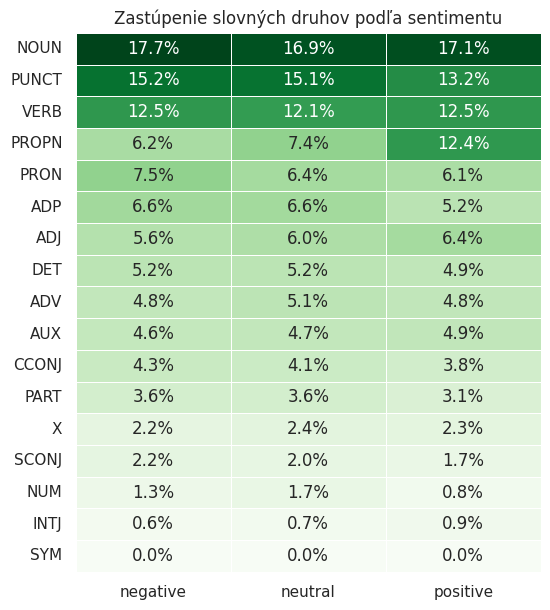

In [35]:
pos_share = pd.crosstab(tokens["upos"], tokens["label"], normalize="columns")
pos_share = pos_share.loc[pos_share.mean(axis=1).sort_values(ascending=False).index]

ax = sns.heatmap(pos_share, annot=True, fmt=".1%", cmap="Greens", cbar=False, linewidths=0.5)
ax.set(title="Zastúpenie slovných druhov podľa sentimentu", xlabel="", ylabel="")
ax.figure.set_size_inches(6, 7)
plt.show()

Zastúpenie slovných druhov je vo všetkých triedach veľmi podobné, najvýraznejší rozdiel je pri vlastných menách (PROPN), ktoré tvoria 12,4 % slov pozitívnych komentárov oproti 6,2 % pri negatívnych; pozitívne komentáre často priamo oslovujú konkrétnu osobu. Negatívne komentáre obsahujú o niečo viac zámen a spojok, čo naznačuje rozvitejšie vety, a približne 2 % slov tvoria vo všetkých triedach nerozpoznané tokeny (X), napríklad slová bez diakritiky, cudzie slová či emoji.

### Najčastejšie slová podľa sentimentu

Používajú sa lemy.

In [36]:
for pos in ["ADJ", "ADV", "VERB"]:
    subset = tokens[tokens["upos"] == pos]
    top = {label: g["lemma"].str.lower().value_counts().head(15).index for label, g in subset.groupby("label")}
    print(pos)
    display(pd.DataFrame(top))

ADJ


,negative,neutral,positive
0,celý,dobrý,dobrý
1,dobrý,celý,super
2,prvý,slovenský,skorý
3,pozitívny,druhý,celý
4,veľký,pozitívny,veľký
5,slovenský,veľký,rád
6,chorý,prvý,skvelý
7,rád,rád,krásny
8,negatívny,malý,rozumný
9,druhý,pekný,výborný


ADV


,negative,neutral,positive
0,tak,tak,dobre
1,tu,tu,tak
2,tam,treba,veľmi
3,teraz,tam,dole
4,treba,teraz,treba
5,dobre,kde,výborne
6,kde,prečo,tu
7,prečo,dobre,teraz
8,potom,dnes,pekne
9,kedy,potom,vždy


VERB


,negative,neutral,positive
0,mať,mať,mať
1,dať,byť,držať
2,ísť,vedieť,dať
3,byť,dať,ďakovať
4,vedieť,ísť,priať
5,môcť,môcť,byť
6,robiť,robiť,vedieť
7,chcieť,chcieť,robiť
8,musieť,musieť,ísť
9,povedať,urobiť,dakovať


Pozitívne komentáre obsahujú jasne hodnotiace prídavné mená („skvelý“, „krásny“, „výborný“, „múdry“, „rozumný“), kým v negatívnych prevládajú tematické slová („celý“, „celoplošný“, „chorý“). Slová „pozitívny“ a „negatívny“ sa vyskytujú najmä v negatívnych a neutrálnych komentároch, kde pravdepodobne neoznačujú sentiment, ale výsledok testu na COVID-19, čo zodpovedá obdobiu celoplošného testovania na Slovensku (október – november 2020).

### Profil komentárov

In [37]:
upos, lemma = tokens["upos"], tokens["lemma"].str.lower()

has_content = upos.isin(["ADJ", "ADV", "VERB", "INTJ"]).groupby(tokens["row"]).any()
only_names = upos.isin(["PROPN", "NOUN", "PUNCT"]).groupby(tokens["row"]).all()
has_neg = (tokens["feats"].str.contains("Polarity=Neg", na=False) | lemma.isin(["nie", "ani"])).groupby(tokens["row"]).any()

profile = pd.DataFrame({
    "bez ADJ/ADV/VERB/INTJ": ~has_content,
    "iba mená a podst. mená": only_names,
    "obsahuje zápor": has_neg,
    "label": df.loc[has_content.index, "label"],
})

display(profile.groupby("label").mean().style.format("{:.1%}"))

,bez ADJ/ADV/VERB/INTJ,iba mená a podst. mená,obsahuje zápor
label,,,
negative,14.5%,6.7%,25.3%
neutral,18.7%,8.4%,19.6%
positive,20.0%,10.6%,10.7%


**Zápor** sa vyskytuje v 25,3 % negatívnych komentárov oproti 10,7 % pozitívnych, je teda silným signálom negatívneho sentimentu a pri predspracovaní ho **nemožno odstrániť ako stop slovo**. Približne 16 % komentárov neobsahuje žiadne prídavné meno, príslovku, sloveso ani citoslovce a zhruba 7 % sa skladá iba z mien a podstatných mien, čo je odhad podielu komentárov bez zjavného nositeľa sentimentu, vrátane orezaných oslovení; tento podiel je najvyšší pri pozitívnych komentároch.

## Detekcia jazyka

In [38]:
!pip install -q lingua-language-detector

In [39]:
from lingua import Language, LanguageDetectorBuilder

detector = LanguageDetectorBuilder.from_languages(
    Language.SLOVAK, Language.CZECH, Language.ENGLISH, Language.GERMAN, Language.HUNGARIAN
).build()
lang = df.loc[mask, "text"].map(lambda t: (l := detector.detect_language_of(t)) and l.name)

display(lang.value_counts(dropna=False).to_frame("komentárov"))

foreign = lang.index[lang.isin(["ENGLISH", "GERMAN", "HUNGARIAN"])]
with pd.option_context("display.max_rows", 300):
    display(df.loc[foreign, ["label", "split", "text"]].assign(jazyk=lang[foreign]).sort_values("jazyk"))

,komentárov
text,
SLOVAK,21153
CZECH,1473
ENGLISH,427
GERMAN,343
HUNGARIAN,334
None,78


,label,split,text,jazyk
9661,negative,train,U think so,ENGLISH
10903,neutral,train,Z next time na one time.,ENGLISH
10902,neutral,train,Live?,ENGLISH
10870,neutral,train,Ja si. Necham. One. Time.,ENGLISH
10838,negative,train,Id*ot,ENGLISH
...,...,...,...,...
11279,negative,train,Aj vás by som do karantény dala,HUNGARIAN
11213,negative,train,FAKTA,HUNGARIAN
11166,negative,train,Toto ti ide kretén,HUNGARIAN
11114,negative,train,Igor,HUNGARIAN


In [40]:
bins = pd.cut(words[lang.index], [0, 2, 5, float("inf")], labels=["1–2 slová", "3–5 slov", "6+ slov"])
display(pd.crosstab(lang.fillna("None"), bins))

text,1–2 slová,3–5 slov,6+ slov
text,,,
CZECH,587,555,331
ENGLISH,265,104,58
GERMAN,293,40,10
HUNGARIAN,261,48,25
None,76,2,0
SLOVAK,3165,4930,13058


In [41]:
foreign = lang.index[lang.isin(["ENGLISH", "GERMAN", "HUNGARIAN"])]
conf = df.loc[foreign, "text"].map(lambda t: detector.compute_language_confidence_values(t)[0].value)

sure = conf.index[(conf >= 0.9) & (words[conf.index] >= 4)]
print(f"Spoľahliví kandidáti: {len(sure)} z {len(foreign)}")

with pd.option_context("display.max_rows", 300):
    display(df.loc[sure, ["label", "split", "text"]].assign(jazyk=lang[sure], istota=conf[sure].round(2)).sort_values("jazyk"))

Spoľahliví kandidáti: 50 z 1104


,label,split,text,jazyk,istota
23,negative,train,some1 hacked my account on aim now i have to make a new one,ENGLISH,0.97
18738,negative,train,sickening .... HOW YOU ARE ENVIOUSLY MISUSING ME and MINE GAME all mega extremely otherwise.. abusing,ENGLISH,1.00
18383,neutral,train,since 2005 and still NOT ALLOWED TO EXIST AS ME and MINE TIMELY GLOBAL !!!!!!!!!! and all other levels all it covered... AS BASTARDS ARE ENVYING BLOCKING PLAYING WASTING STEALING EXPLOITING >...mega sickening,ENGLISH,1.00
18372,neutral,train,One time you will improve your English so until Next time keep trying Yegor,ENGLISH,0.99
18322,negative,train,If you make jokes from your stupidity,ENGLISH,0.90
18283,negative,train,Next next time without you ... I believe :-) ... Together with U2: better without you ... https://www.youtube.com/watch?v=ujNeHIo7oTE,ENGLISH,0.95
14726,neutral,train,Your flowers are beautifull,ENGLISH,0.98
13904,negative,train,Lockdown v Nemcku https://www.dw.com/en/coronavirus-germany-to-impose-one-month-partial-lockdown/a-55421241,ENGLISH,0.93
13232,neutral,train,Keđ si prìde NAKA pre Fica Kaliñàka,ENGLISH,0.99
11687,negative,train,Once upon a time the God created Earth and Seas and then come Hero from universum named Igor Matovic (probably in some relationship with Darth Vader) And show over the whole world with Covid has began.,ENGLISH,1.00


Detekcia jazyka (knižnica Lingua) označila 89 % komentárov ako slovenské a 6 % ako české. Ďalších 1 104 komentárov bolo označených ako anglické, nemecké alebo maďarské, no tieto detekcie sa sústreďujú v textoch s jedným či dvoma slovami, kde určenie jazyka nie je spoľahlivé. Po ponechaní iba detekcií s vysokou istotou a aspoň štyrmi slovami ostalo 50 kandidátov, z ktorých ručnou kontrolou bolo potvrdených 45 cudzojazyčných komentárov. Pri príprave dát je vhodné prítomnosť cudzojazyčných komentárov preskúmať detailnejšie.

## Zhrnutie

Dataset obsahuje 23 825 slovenských komentárov rozdelených na trénovaciu (19 148, 80 %) a testovaciu (4 677, 20 %) množinu s piatimi stĺpcami: `id`, `label`, `user`, `created_at` a `text`. Žiadny stĺpec neobsahuje chýbajúce hodnoty, dataset však obsahuje 17 prázdnych textov.

**Triedy.** Dataset je výrazne nevyvážený: 70 % negatívnych, 21 % neutrálnych a 9 % pozitívnych komentárov. Rozdelenie tried je v oboch splitoch takmer totožné.

**Používatelia.** Dataset obsahuje 13 121 unikátnych používateľov, väčšina prispela jedným alebo dvoma komentármi (medián 1) a najaktívnejších 10 používateľov tvorí iba 1,3 % dát. Medzi train a test neexistuje prekryv používateľov, dáta boli pravdepodobne rozdelené podľa autorov. Mená majú prevažne tvar „Meno Priezvisko“ (86 % dvojslovných, 13 % trojslovných); v jednom prípade je v stĺpci `user` uložený text komentára.

**Čas.** Komentáre pochádzajú z roku 2020, prevažne z obdobia október – november, a časové známky majú presnosť na minúty. Výnimkou je 61 záznamov z roku 2009 na začiatku oboch splitov, ktorých metadáta (id, používateľ, čas) pochádzajú zrejme z iného datasetu; dva z nich obsahujú pôvodné anglické tweety.

**Duplicity.** Úplne zhodné záznamy sú iba 3. Opakovaný text má 1 556 záznamov, ide prevažne o krátke oslovenia („Pán premiér“, „Igor“) a začiatky viet, čo naznačuje, že pri zbere dát bol uložený iba prvý riadok komentára. 1 179 z týchto záznamov (približne 5 % datasetu) má pri rovnakom texte rozdielne labely.

**Dĺžka textu.** Komentáre sú prevažne krátke (medián 7 slov, štvrtina má najviac 3 slová) s dlhým chvostom do 206 slov. Pozitívne komentáre sú najkratšie, negatívne najdlhšie; rozdelenie dĺžok je v oboch splitoch rovnaké.

**Slovné druhy.** Zastúpenie slovných druhov je medzi triedami podobné; pozitívne komentáre obsahujú dvojnásobne viac vlastných mien a výrazný hodnotiaci slovník („skvelý“, „ďakovať“, „gratulovať“), negatívne častejšie zápor (25 % oproti 11 % pri pozitívnych). Slovník odráža obdobie celoplošného testovania na COVID-19: slová „pozitívny“ a „negatívny“ často označujú výsledok testu, nie sentiment. Približne 16 % komentárov neobsahuje žiadny slovný druh typicky nesúci sentiment a časť textov je písaná bez diakritiky.

## Odporúčania pre prípravu dát

- Odstrániť 3 úplne zhodné záznamy, 17 prázdnych textov a 2 anglické tweety.
- Pri záznamoch z roku 2009 ponechať text a label, časovú známku považovať za chýbajúcu.
- Odstrániť z trénovacej množiny opakované texty s rozdielnymi labelmi; testovaciu množinu ponechať kvôli porovnateľnosti.
- Pri modelovaní zohľadniť nevyváženosť tried (macro F1, váhovanie tried).
- Pri vyhodnocovaní sledovať úspešnosť zvlášť na krátkych komentároch.
- Zápor („nie“, „ani“, predpona „ne-“) neodstraňovať ako stop slová, je silným signálom negatívneho sentimentu.
- Zvážiť normalizáciu diakritiky alebo lematizáciu, aby sa zjednotili rôzne podoby rovnakého slova („ďakovať“ / „dakovať“).
- Detailnejšie preskúmať cudzojazyčné komentáre a zvážiť ich odránenie.